# AML Baseline 1 — Independent EfficientNet-B0 | Google Colab | E3 Dropout Tuning (Patience 15)

**Stage 1 — Training and development validation ONLY.** This notebook uses the **same model, transforms, dataset splits, optimizer, learning-rate scheduler, progress format and checkpoint-selection rule** as the uploaded E1/E2 notebook.

**Question:** Holding the reference learning rates constant, does changing dropout from **0.2** to **0.3** or **0.4** improve generalisation?

| Fixed configuration | Value |
|---|---|
| Backbone LR / Head LR | `1e-5` / `1e-3` |
| Maximum epochs / Early stopping patience | `30` / `15` |
| Batch size / Weight decay | `32` / `1e-4` |
| Reference checkpoints | `C1_reference_P15` and `D1_reference_P15` (dropout `0.2`) |
| New Crop runs | `C4_dropout_03_P15`, `C5_dropout_04_P15` |
| New Disease runs | `D4_dropout_03_P15`, `D5_dropout_04_P15` |

**Dataset:** `train_fit.csv` (6,905), `val_seen.csv` (695), `val_unseen.csv` (400). **No Stage 2 fine-tuning. No official test evaluation.** Existing E1/E2 results are left untouched.

## Cell 1 — Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Cell 2 — Imports, Drive paths and shared settings

**Edit only `DRIVE_PROJECT`** if your My Drive shortcut has a different location. Each CNN hyperparameters appear immediately before its own training section.

In [ ]:
from pathlib import Path
import os, sys, shutil, subprocess, json, random, time, gc, copy, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import EfficientNet_B0_Weights
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

DRIVE_PROJECT = Path('/content/drive/MyDrive/DPD-Small')
LOCAL_PROJECT = Path('/content/DPD-Small')
RESULTS = Path('/content/drive/MyDrive/AML_B1_Clean_Results')
SEED = 42
NUM_WORKERS = 2
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'

assert DRIVE_PROJECT.exists(), f'Cannot find Drive project: {DRIVE_PROJECT}'
assert DEVICE.type == 'cuda', 'Enable a GPU: Runtime > Change runtime type > GPU'
RESULTS.mkdir(parents=True, exist_ok=True)
for folder in [
    'experiments/crop', 'experiments/disease',
    'development/combined_validation', 'development/experiment_comparisons',
    'development/dropout_tuning',
]:
    (RESULTS / folder).mkdir(parents=True, exist_ok=True)

DEVELOPMENT_DIR = RESULTS / 'development'
DROPOUT_DIR = DEVELOPMENT_DIR / 'dropout_tuning'
DROPOUT_DIR.mkdir(parents=True, exist_ok=True)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)
print('Project:', DRIVE_PROJECT)
print('Results:', RESULTS)

GPU: Tesla T4
PyTorch: 2.14.1+cu130
Project: /content/drive/MyDrive/DPD-Small
Results: /content/drive/MyDrive/AML_B1_Clean_Results


## Cell 3 — Copy all images and CSVs to Colab local storage (resumable)

Uses `rsync` so an interrupted copy can resume. This is the slowest preparation cell when Drive contains thousands of individual files. **Do not run model training until Cell 5 finds all required files.**

In [ ]:
LOCAL_PROJECT.mkdir(parents=True, exist_ok=True)

def find_child(parent, name):
    hits = [p for p in parent.iterdir() if p.name.lower() == name.lower()]
    if len(hits) != 1:
        raise FileNotFoundError(f'Expected {name} in {parent}; found {hits}')
    return hits[0]

start_copy = time.time()
for dirname in ['images', 'splits_v2']:
    src = find_child(DRIVE_PROJECT, dirname)
    dst = LOCAL_PROJECT / dirname
    dst.mkdir(parents=True, exist_ok=True)
    print(f'Copy/resume: {src} -> {dst}', flush=True)
    subprocess.run([
        'rsync', '-rt', '--size-only', '--info=progress2',
        str(src) + '/', str(dst) + '/'
    ], check=True)

for filename in ['DPD_Small_train.csv', 'DPD_Small_test_seen.csv', 'DPD_Small_test_unseen.csv']:
    src = find_child(DRIVE_PROJECT, filename)
    shutil.copy2(src, LOCAL_PROJECT / filename)
    print('Copied CSV:', filename)

print(f'Copy complete in {(time.time()-start_copy)/60:.1f} min')

Copy/resume: /content/drive/MyDrive/DPD-Small/images -> /content/DPD-Small/images
Copy/resume: /content/drive/MyDrive/DPD-Small/splits_v2 -> /content/DPD-Small/splits_v2
Copied CSV: DPD_Small_train.csv
Copied CSV: DPD_Small_test_seen.csv
Copied CSV: DPD_Small_test_unseen.csv
Copy complete in 6.9 min


## Cell 4 — Load CSV files and verify the composition-aware split

Read the original headerless files correctly. Check **6,905 + 695 + 400 = 8,000**, no image overlap, and held-out crop–disease pairs are unseen to development training.

In [ ]:
COLUMNS = ['filename','crop_id','disease_id','composition_id',
           'crop_name','disease_name','composition_name']

def read_original_csv(path):
    # Original lecturer files have no header; also handles an unexpected header safely.
    with open(path, 'r', encoding='utf-8-sig') as f:
        first = f.readline().strip().split(',')
    has_header = first[0].strip().lower() == 'filename'
    df = pd.read_csv(path, header=0 if has_header else None,
                     names=COLUMNS, encoding='utf-8-sig')
    for col in ['crop_id','disease_id','composition_id']:
        df[col] = pd.to_numeric(df[col], errors='raise').astype(int)
    return df

train_df = pd.read_csv(LOCAL_PROJECT/'splits_v2/train_fit.csv')
val_seen_df = pd.read_csv(LOCAL_PROJECT/'splits_v2/val_seen.csv')
val_unseen_df = pd.read_csv(LOCAL_PROJECT/'splits_v2/val_unseen.csv')
full_train_df = read_original_csv(LOCAL_PROJECT/'DPD_Small_train.csv')
test_seen_df = read_original_csv(LOCAL_PROJECT/'DPD_Small_test_seen.csv')
test_unseen_df = read_original_csv(LOCAL_PROJECT/'DPD_Small_test_unseen.csv')

expected = {'train':6905,'val_seen':695,'val_unseen':400,'full_train':8000,
            'test_seen':2000,'test_unseen':1448}
datasets = {'train':train_df,'val_seen':val_seen_df,'val_unseen':val_unseen_df,
            'full_train':full_train_df,'test_seen':test_seen_df,'test_unseen':test_unseen_df}
for name, df in datasets.items():
    assert len(df) == expected[name], f'{name}: got {len(df)}, expected {expected[name]}'
    assert set(COLUMNS).issubset(df.columns), f'Missing metadata columns in {name}'
    assert df.filename.is_unique, f'Duplicate filenames in {name}'
    print(f'{name:12s}: {len(df):,} images')

file_sets = [set(df.filename) for df in (train_df,val_seen_df,val_unseen_df)]
assert not any(file_sets[i] & file_sets[j] for i in range(3) for j in range(i+1,3))
assert set().union(*file_sets) == set(full_train_df.filename)
assert not (set(full_train_df.filename) & (set(test_seen_df.filename)|set(test_unseen_df.filename)))
assert set(test_seen_df.filename).isdisjoint(set(test_unseen_df.filename))

def pairs(df):
    return set(map(tuple,df[['crop_id','disease_id']].astype(int).to_numpy()))

assert pairs(val_seen_df).issubset(pairs(train_df))
assert pairs(val_unseen_df).isdisjoint(pairs(train_df)|pairs(val_seen_df))
assert set(val_unseen_df.crop_id).issubset(set(train_df.crop_id))
assert set(val_unseen_df.disease_id).issubset(set(train_df.disease_id))
print('Split separation and unseen-composition coverage: PASS')
display(train_df.head(3))

train       : 6,905 images
val_seen    : 695 images
val_unseen  : 400 images
full_train  : 8,000 images
test_seen   : 2,000 images
test_unseen : 1,448 images
Split separation and unseen-composition coverage: PASS


,filename,crop_id,disease_id,composition_id,crop_name,disease_name,composition_name
0,BLSD_banana_sigatoka_615.jpeg,2,26,28,banana,sigatoka,banana_sigatoka
1,PD_paddy_bacterial_panicle_blight_1285.jpg,33,120,195,paddy,bacterial_panicle_blight,paddy_bacterial_panicle_blight
2,PWV2_peach_leaf_curl_6128.jpg,36,57,219,peach,curl,peach_curl


## Cell 5 — Index local image files and verify every CSV filename

If an interrupted copy left missing files, rerun Cell 3; do not skip this check.

In [ ]:
image_dir = LOCAL_PROJECT / 'images'
assert image_dir.is_dir(), f'No images folder: {image_dir}'
image_lookup = {}
duplicates = []
for p in tqdm(image_dir.rglob('*'), desc='Indexing local images'):
    if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}:
        if p.name in image_lookup:
            duplicates.append(p.name)
        image_lookup[p.name] = p
assert not duplicates, f'Duplicate basenames: {duplicates[:8]}'
needed = set().union(*(set(df.filename) for df in datasets.values()))
missing = needed - set(image_lookup)
print('Indexed:', len(image_lookup), '| Required unique:',len(needed),'| Missing:',len(missing))
assert not missing, f'Missing images (rerun Cell 3): {list(missing)[:10]}'
print('All required images are available locally.')

Indexing local images: 0it [00:00, ?it/s]

Indexed: 11469 | Required unique: 11448 | Missing: 0
All required images are available locally.


## Cell 6 — Training augmentation and deterministic validation/test preprocessing

Both networks use identical transforms. Training adds light augmentation; validation/testing use no random transformations.

In [ ]:
MEAN = (0.485,0.456,0.406)
STD = (0.229,0.224,0.225)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85,1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN,STD),
])
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN,STD),
])
def de_normalize(t):
    mu = torch.tensor(MEAN).view(3,1,1)
    sd = torch.tensor(STD).view(3,1,1)
    return (t.detach().cpu()*sd+mu).clamp(0,1).permute(1,2,0).numpy()
print('Transforms ready: random train augmentation; deterministic validation/test.')

Transforms ready: random train augmentation; deterministic validation/test.


## Cell 7 — Visual comparison: original vs two augmented views vs validation image

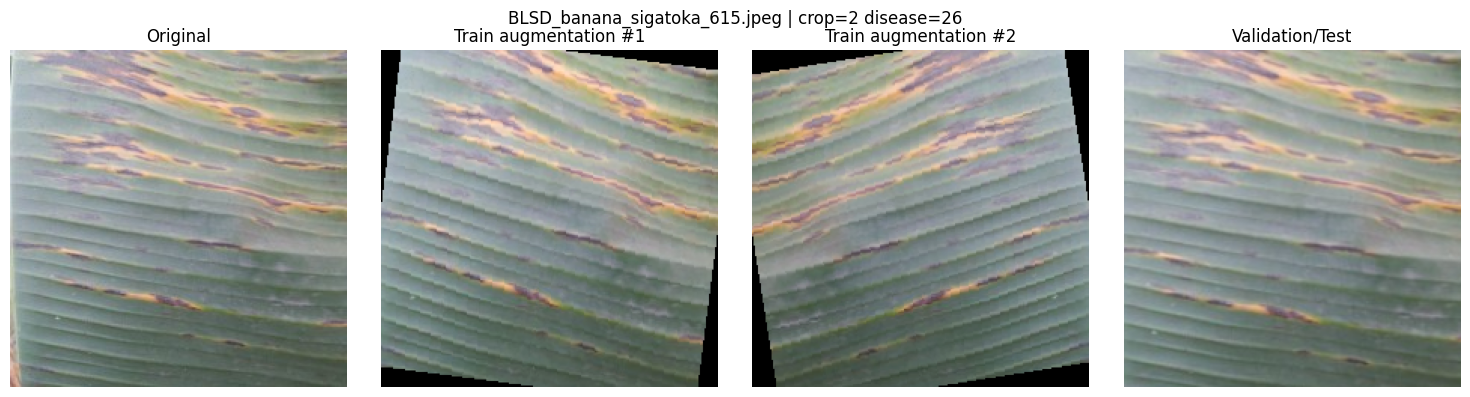

In [ ]:
r = train_df.iloc[0]
original = Image.open(image_lookup[r.filename]).convert('RGB')
fig, axes = plt.subplots(1,4,figsize=(15,4))
axes[0].imshow(original)
axes[1].imshow(de_normalize(train_transform(original)))
axes[2].imshow(de_normalize(train_transform(original)))
axes[3].imshow(de_normalize(eval_transform(original)))
for ax,ttl in zip(axes,['Original','Train augmentation #1','Train augmentation #2','Validation/Test']):
    ax.set_title(ttl)
    ax.axis('off')
plt.suptitle(f'{r.filename} | crop={r.crop_id} disease={r.disease_id}')
plt.tight_layout()
plt.show()

## Cell 8 — Shared PyTorch Dataset & DataLoaders

Every image returns both crop and disease labels. Crop training uses **only `crop_y`**, disease training uses **only `disease_y`**. Class-index mapping follows the original CSV IDs.

In [ ]:
crop_ids = sorted(map(int,full_train_df.crop_id.unique()))
disease_ids = sorted(map(int,full_train_df.disease_id.unique()))
assert len(crop_ids)==55, f'Expected 55 crops, got {len(crop_ids)}'
assert len(disease_ids)==175, f'Expected 175 diseases, got {len(disease_ids)}'
crop_to_idx = {c:i for i,c in enumerate(crop_ids)}
disease_to_idx = {d:i for i,d in enumerate(disease_ids)}
idx_to_crop = {i:c for c,i in crop_to_idx.items()}
idx_to_disease = {i:d for d,i in disease_to_idx.items()}
(RESULTS/'class_mapping.json').write_text(json.dumps({'crop_ids':crop_ids,'disease_ids':disease_ids},indent=2))

class PlantDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(image_lookup[str(row.filename)]) as im:
            x = self.transform(im.convert('RGB'))
        return (x, crop_to_idx[int(row.crop_id)], disease_to_idx[int(row.disease_id)])

def loader_for(df, train=False, batch_size=32):
    return DataLoader(
        PlantDataset(df, train_transform if train else eval_transform),
        batch_size=batch_size, shuffle=train, num_workers=NUM_WORKERS,
        pin_memory=True, persistent_workers=(NUM_WORKERS>0)
    )

seen_loader = loader_for(val_seen_df)
unseen_loader = loader_for(val_unseen_df)
print('Class mappings: crops=',len(crop_ids),'diseases=',len(disease_ids))
print('Validation batches:',len(seen_loader),'seen and',len(unseen_loader),'unseen')

Class mappings: crops= 55 diseases= 175
Validation batches: 22 seen and 13 unseen


## Cell 9 — Shared EfficientNet-B0 model, progress bars, evaluation & training utilities

Defines functions only: **no training starts here**. Training progress appears as a `tqdm` batch bar plus **one concise metric line per epoch**. Every experiment saves a unique best-H checkpoint and its seen/unseen validation score arrays.

In [ ]:
def make_model(task, pretrained=True, dropout=0.2):
    nclasses = {'crop':55,'disease':175}[task]
    weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    dim = model.classifier[1].in_features
    model.classifier = nn.Sequential(nn.Dropout(dropout),nn.Linear(dim,nclasses))
    return model.to(DEVICE)

def make_optimizer(model, cfg):
    return torch.optim.AdamW([
        {'params':model.features.parameters(), 'lr':cfg['backbone_lr']},
        {'params':model.classifier.parameters(), 'lr':cfg['head_lr']}
    ],weight_decay=cfg['weight_decay'])

def harmonic(a,b):
    return 0.0 if a+b==0 else 2*a*b/(a+b)

def experiment_path(task, name):
    return RESULTS/'experiments'/task/name

@torch.no_grad()
def evaluate_task(model, loader, task):
    model.eval()
    total_n = total_loss = correct1 = correct5 = 0
    criterion = nn.CrossEntropyLoss()
    for x, yc, yd in loader:
        x = x.to(DEVICE,non_blocking=True)
        y = (yc if task=='crop' else yd).to(DEVICE,non_blocking=True)
        with torch.autocast('cuda',enabled=AMP):
            logits = model(x)
            loss = criterion(logits,y)
        total_n += y.size(0)
        total_loss += loss.item()*y.size(0)
        top5 = logits.topk(5,dim=1).indices
        correct1 += (top5[:,0]==y).sum().item()
        correct5 += (top5==y[:,None]).any(1).sum().item()
    return {'loss':total_loss/total_n, 'top1':correct1/total_n,'top5':correct5/total_n}

def training_epoch(model, loader, task, optimizer, scaler, label):
    model.train()
    criterion = nn.CrossEntropyLoss()
    total_n=correct=0
    total_loss=0.0
    bar=tqdm(loader,desc=label,leave=False)
    for x,yc,yd in bar:
        x=x.to(DEVICE,non_blocking=True)
        y=(yc if task=='crop' else yd).to(DEVICE,non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda',enabled=AMP):
            logits=model(x)
            loss=criterion(logits,y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        n=y.size(0)
        total_n+=n
        total_loss+=float(loss.detach())*n
        correct+=(logits.argmax(1)==y).sum().item()
        bar.set_postfix(loss=f'{total_loss/total_n:.3f}',acc=f'{correct/total_n:.1%}')
    return {'loss':total_loss/total_n,'top1':correct/total_n}

@torch.no_grad()
def predict_log_probs(model, loader):
    model.eval()
    outputs=[]
    for x,_,_ in loader:
        x=x.to(DEVICE,non_blocking=True)
        with torch.autocast('cuda',enabled=AMP):
            logits=model(x)
        outputs.append(F.log_softmax(logits.float(),dim=1).cpu().numpy())
    return np.concatenate(outputs,axis=0)

def save_ckpt(path, model, task, cfg, epoch, metric=None):
    path.parent.mkdir(parents=True,exist_ok=True)
    torch.save({
        'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
        'task':task, 'epoch':int(epoch), 'config':copy.deepcopy(cfg),
        'crop_ids':crop_ids,'disease_ids':disease_ids,'seed':SEED,
        'selection_metric':metric
    },path)

def load_model(path, expected_task):
    ck=torch.load(path,map_location='cpu',weights_only=False)
    assert ck['task']==expected_task
    assert ck['crop_ids']==crop_ids and ck['disease_ids']==disease_ids
    model=make_model(expected_task,pretrained=False,
                     dropout=ck.get('config',{}).get('dropout',0.2))
    model.load_state_dict(ck['state_dict'])
    return model,ck

def run_experiment(task,name,cfg):
    """Each model independently chooses best epoch by its own seen/unseen class H."""
    set_seed(SEED)
    out=experiment_path(task,name)
    if (out/'best.pt').exists():
        raise FileExistsError(f'Experiment {out} already exists. Change run name to avoid overwriting.')
    out.mkdir(parents=True,exist_ok=True)
    (out/'config.json').write_text(json.dumps(cfg,indent=2))
    model=make_model(task,pretrained=True,dropout=cfg['dropout'])
    optimizer=make_optimizer(model,cfg)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=cfg['epochs'])
    scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    train_loader=loader_for(train_df,train=True,batch_size=cfg['batch_size'])
    best_h=-1.0; best_epoch=None; patience_count=0; history=[]
    try:
        for epoch in range(1,cfg['epochs']+1):
            t=time.time()
            tr=training_epoch(model,train_loader,task,optimizer,scaler,f'{task.upper()} {name} {epoch}/{cfg["epochs"]}')
            sv=evaluate_task(model,seen_loader,task)
            uv=evaluate_task(model,unseen_loader,task)
            h=harmonic(sv['top1'],uv['top1'])
            improved=h>best_h+1e-9
            if improved:
                best_h=h;best_epoch=epoch;patience_count=0
                save_ckpt(out/'best.pt',model,task,cfg,epoch,metric=h)
                # Validation predictions are stored for pairing, never from test images.
                np.savez_compressed(out/'best_validation.npz',
                    seen=predict_log_probs(model,seen_loader),
                    unseen=predict_log_probs(model,unseen_loader))
            else:
                patience_count+=1
            history.append({
                'epoch':epoch,'train_loss':tr['loss'],'train_acc':tr['top1'],
                'seen_loss':sv['loss'],'seen_acc':sv['top1'],'seen_top5':sv['top5'],
                'unseen_loss':uv['loss'],'unseen_acc':uv['top1'],'unseen_top5':uv['top5'],
                'harmonic_mean':h,'best_h':best_h,'seconds':time.time()-t
            })
            pd.DataFrame(history).to_csv(out/'history.csv',index=False)
            scheduler.step()
            print(f'{task.upper():7s} {name} | Epoch {epoch:02d}/{cfg["epochs"]} | '
                  f'Train Loss {tr["loss"]:.4f} | Train Acc {tr["top1"]:.2%} | '
                  f'Seen Val {sv["top1"]:.2%} | Unseen Val {uv["top1"]:.2%} | '
                  f'H {h:.2%} | Best H {best_h:.2%} | Patience {patience_count}/{cfg["patience"]}',flush=True)
            if cfg['early_stopping'] and patience_count>=cfg['patience']:
                print(f'EARLY STOPPING: {task} | best epoch={best_epoch} | best H={best_h:.2%}')
                break
    finally:
        del model,optimizer,scheduler,scaler,train_loader
        gc.collect()
        if DEVICE.type=='cuda': torch.cuda.empty_cache()
    print(f'FINISHED {task}/{name}: best epoch={best_epoch} | H={best_h:.2%}')
    return pd.DataFrame(history)

def plot_experiment(task,name):
    df=pd.read_csv(experiment_path(task,name)/'history.csv')
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for col in ['train_loss','seen_loss','unseen_loss']:
        axes[0].plot(df.epoch,df[col],label=col)
    for col in ['train_acc','seen_acc','unseen_acc']:
        axes[1].plot(df.epoch,df[col]*100,label=col)
    axes[2].plot(df.epoch,df.harmonic_mean*100,label='Current H')
    axes[2].plot(df.epoch,df.best_h*100,label='Best H',linestyle='--')
    for ax,title in zip(axes,['Cross-entropy loss','Accuracy (%)','Individual harmonic mean (%)']):
        ax.set_title(title);ax.set_xlabel('Epoch');ax.grid(alpha=.2);ax.legend()
    plt.suptitle(f'{task.upper()} — {name}');plt.tight_layout()
    plt.savefig(experiment_path(task,name)/'curves.png',dpi=180)
    plt.show()

print('Reusable training functions ready. No CNN has been trained by this cell.')

# E3-only safeguard: completed runs are skipped, partial runs must be reviewed.
# The base training function above is unchanged to preserve E1/E2 consistency.
def run_dropout_experiment(task, name, cfg):
    out = experiment_path(task, name)
    marker = out / 'STAGE1_COMPLETE.json'
    if marker.exists():
        assert all((out / f).exists() for f in ('best.pt','history.csv','best_validation.npz')), (task,name)
        print(f'SKIP completed {task}/{name} (all original results preserved).')
        return
    if out.exists() and any(out.iterdir()):
        raise RuntimeError(
            f'Existing files for {task}/{name}: {out}. '
            'Review this partial run before retrying; do not overwrite results.'
        )
    hist = run_experiment(task, name, cfg)
    out = experiment_path(task, name)
    assert all((out / f).exists() for f in ('best.pt','history.csv','best_validation.npz'))
    ck = torch.load(out/'best.pt',map_location='cpu',weights_only=False)
    marker.write_text(json.dumps({
        'task': task, 'experiment': name, 'stage': 'Stage 1 development only',
        'config': cfg, 'last_epoch': int(hist.epoch.max()),
        'best_epoch': int(ck['epoch']),
        'best_individual_validation_H': float(ck['selection_metric'])
    },indent=2))
    print(f'COMPLETE {task}/{name} — Development validation only.')


Reusable training functions ready. No CNN has been trained by this cell.


## Cell 10 — CROP CNN: set dropout hyperparameters (easy to edit before training)

As in E1/E2, **configuration and training are separate**. Keep reference LRs `1e-5 / 1e-3`, batch size 32, maximum 30 epochs, patience 15, and weight decay `1e-4`. Only dropout changes. Existing reference C1-P15 is **loaded for comparison**, not trained here.

In [ ]:
# Stage 1 — Dropout study, Crop CNN (55 classes); DEVELOPMENT VALIDATION ONLY.
CROP_EXPERIMENTS = {
    'C4_dropout_03_P15': dict(backbone_lr=1e-5,head_lr=1e-3,batch_size=32,
                              epochs=30,patience=15,early_stopping=True,
                              weight_decay=1e-4,dropout=0.3),
    'C5_dropout_04_P15': dict(backbone_lr=1e-5,head_lr=1e-3,batch_size=32,
                              epochs=30,patience=15,early_stopping=True,
                              weight_decay=1e-4,dropout=0.4),
}
REFERENCE_CROP_RUN = 'C1_reference_P15'  # Reference dropout=0.2: DO NOT RETRAIN.
RUN_CROP = ['C4_dropout_03_P15','C5_dropout_04_P15']
# To train only one: RUN_CROP = ['C4_dropout_03_P15']
# To review existing results without training: RUN_CROP = []
assert (experiment_path('crop',REFERENCE_CROP_RUN)/'best_validation.npz').exists(), (
    f'Missing reference: crop/{REFERENCE_CROP_RUN}. Mount the same Results Drive.'
)
print('Reference crop (existing):',REFERENCE_CROP_RUN)
print('New crop experiments:',RUN_CROP)
for name in RUN_CROP: print(name,CROP_EXPERIMENTS[name])

Reference crop (existing): C1_reference_P15
New crop experiments: ['C4_dropout_03_P15', 'C5_dropout_04_P15']
C4_dropout_03_P15 {'backbone_lr': 1e-05, 'head_lr': 0.001, 'batch_size': 32, 'epochs': 30, 'patience': 15, 'early_stopping': True, 'weight_decay': 0.0001, 'dropout': 0.3}
C5_dropout_04_P15 {'backbone_lr': 1e-05, 'head_lr': 0.001, 'batch_size': 32, 'epochs': 30, 'patience': 15, 'early_stopping': True, 'weight_decay': 0.0001, 'dropout': 0.4}


## Cell 11 — CROP CNN: train → seen/unseen validation → crop H → best checkpoint

Same epoch progress print, same ImageNet pretrained EfficientNet-B0, same validation-H checkpoint selection and `curves.png` as E1/E2. Creates **new E3 folders only**; skips completed E3 runs and blocks overwriting partially populated folders. Training costs GPU compute units.


=== CROP: C4_dropout_03_P15 ===
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 153MB/s]


CROP C4_dropout_03_P15 1/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C4_dropout_03_P15 | Epoch 01/30 | Train Loss 1.4968 | Train Acc 66.85% | Seen Val 74.24% | Unseen Val 53.50% | H 62.19% | Best H 62.19% | Patience 0/15


CROP C4_dropout_03_P15 2/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C4_dropout_03_P15 | Epoch 02/30 | Train Loss 0.6651 | Train Acc 83.81% | Seen Val 79.28% | Unseen Val 56.75% | H 66.15% | Best H 66.15% | Patience 0/15


... (48 outputs left out)

CROP C4_dropout_03_P15 27/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C4_dropout_03_P15 | Epoch 27/30 | Train Loss 0.0614 | Train Acc 98.38% | Seen Val 88.20% | Unseen Val 65.25% | H 75.01% | Best H 76.67% | Patience 14/15


CROP C4_dropout_03_P15 28/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C4_dropout_03_P15 | Epoch 28/30 | Train Loss 0.0665 | Train Acc 98.28% | Seen Val 88.06% | Unseen Val 65.00% | H 74.79% | Best H 76.67% | Patience 15/15
EARLY STOPPING: crop | best epoch=13 | best H=76.67%
FINISHED crop/C4_dropout_03_P15: best epoch=13 | H=76.67%
COMPLETE crop/C4_dropout_03_P15 — Development validation only.


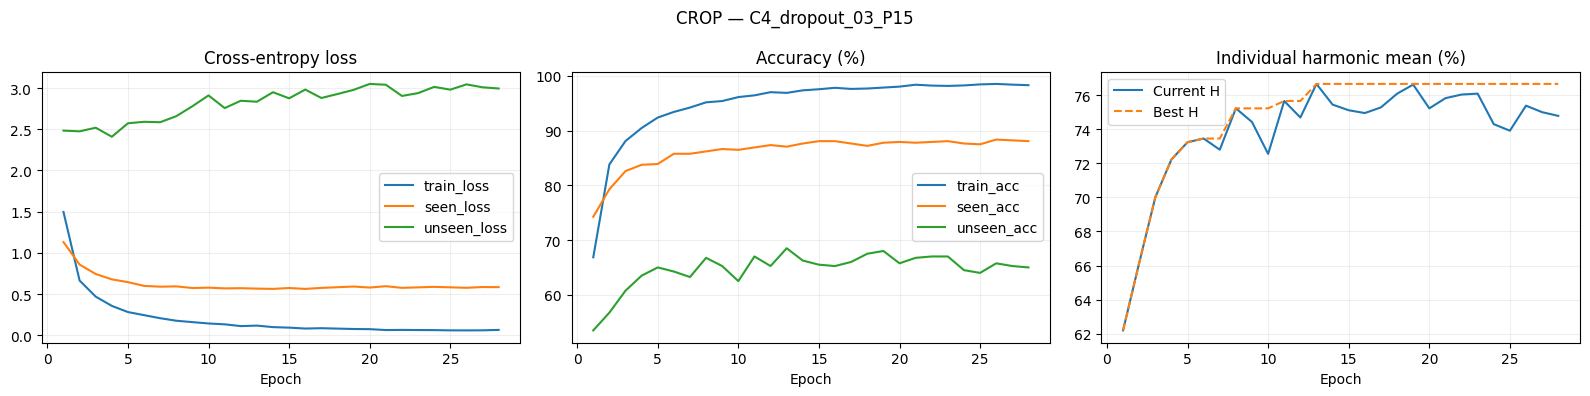


=== CROP: C5_dropout_04_P15 ===


CROP C5_dropout_04_P15 1/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C5_dropout_04_P15 | Epoch 01/30 | Train Loss 1.5453 | Train Acc 65.26% | Seen Val 73.24% | Unseen Val 52.75% | H 61.33% | Best H 61.33% | Patience 0/15


CROP C5_dropout_04_P15 2/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C5_dropout_04_P15 | Epoch 02/30 | Train Loss 0.7045 | Train Acc 82.91% | Seen Val 78.71% | Unseen Val 57.50% | H 66.45% | Best H 66.45% | Patience 0/15


CROP C5_dropout_04_P15 3/30:   0%|          | 0/216 [00:00<?, ?it/s]

... (33 outputs left out)

CROP C5_dropout_04_P15 20/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C5_dropout_04_P15 | Epoch 20/30 | Train Loss 0.0897 | Train Acc 97.47% | Seen Val 87.19% | Unseen Val 67.00% | H 75.77% | Best H 75.82% | Patience 14/15


CROP C5_dropout_04_P15 21/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C5_dropout_04_P15 | Epoch 21/30 | Train Loss 0.0916 | Train Acc 97.19% | Seen Val 87.48% | Unseen Val 65.75% | H 75.07% | Best H 75.82% | Patience 15/15
EARLY STOPPING: crop | best epoch=6 | best H=75.82%
FINISHED crop/C5_dropout_04_P15: best epoch=6 | H=75.82%
COMPLETE crop/C5_dropout_04_P15 — Development validation only.


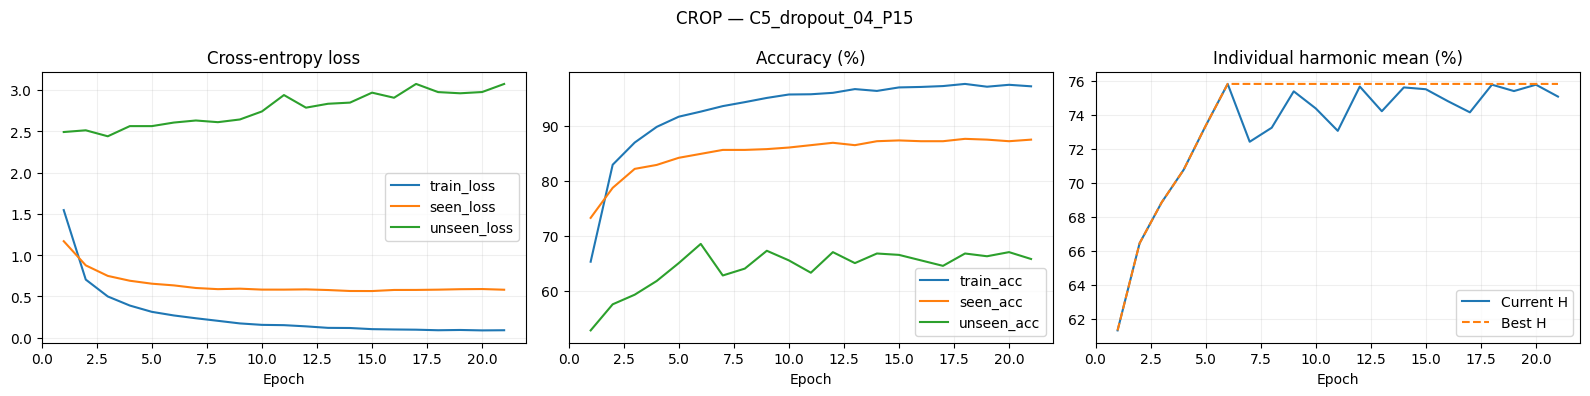

Crop dropout study training cell finished — NO OFFICIAL TEST.


In [ ]:
# STAGE 1 DEVELOPMENT VALIDATION ONLY — Crop dropout 0.3 / 0.4.
for name in RUN_CROP:
    print(f'\n=== CROP: {name} ===', flush=True)
    run_dropout_experiment('crop',name,CROP_EXPERIMENTS[name])
    if (experiment_path('crop',name)/'history.csv').exists():
        plot_experiment('crop',name)
print('Crop dropout study training cell finished — NO OFFICIAL TEST.')

## Cell 12 — CROP CNN: development validation experiment summary

Compare `C1_reference_P15` (dropout 0.2) with C4 (0.3) and C5 (0.4). The best checkpoint for **each individual model** is chosen by its own Seen/Unseen validation harmonic mean. **Best individual H is not necessarily best composition H.**

In [ ]:
# Read only the three intended crop dropout configurations.
# Never include the original patience-5 C1 in this controlled comparison.
def dropout_experiment_summary(task, runs):
    rows=[]
    for name in runs:
        folder=experiment_path(task,name)
        required=['best.pt','history.csv','best_validation.npz']
        missing=[f for f in required if not (folder/f).exists()]
        assert not missing, f'Missing {task}/{name} files: {missing}'
        if name not in (REFERENCE_CROP_RUN, REFERENCE_DISEASE_RUN):
            assert (folder/'STAGE1_COMPLETE.json').exists(), f'Unfinished E3 run: {task}/{name}'
        ck=torch.load(folder/'best.pt',map_location='cpu',weights_only=False)
        history=pd.read_csv(folder/'history.csv')
        epoch=int(ck['epoch'])
        best_rows=history.loc[history.epoch==epoch]
        assert len(best_rows)==1,(name,epoch)
        best=best_rows.iloc[0]
        cfg=ck['config']
        assert cfg['patience']==15 and cfg['epochs']==30, f'Inconsistent protocol: {name}'
        assert cfg['backbone_lr']==1e-5 and cfg['head_lr']==1e-3, f'LR differs: {name}'
        rows.append(dict(experiment=name,dropout=float(cfg['dropout']),
            best_epoch=epoch,trained_epochs=int(history.epoch.max()),
            seen_validation_top1=float(best['seen_acc']),
            unseen_validation_top1=float(best['unseen_acc']),
            seen_validation_top5=float(best['seen_top5']),
            unseen_validation_top5=float(best['unseen_top5']),
            best_individual_H=float(ck['selection_metric']),
            backbone_lr=cfg['backbone_lr'],head_lr=cfg['head_lr'],
            patience=cfg['patience']))
    result=pd.DataFrame(rows).sort_values('best_individual_H',ascending=False).reset_index(drop=True)
    print(f'\nSTAGE 1 — {task.upper()} CNN DROPOUT DEVELOPMENT VALIDATION (NOT OFFICIAL TEST)')
    display(result.style.format({
        'dropout':'{:.1f}', 'seen_validation_top1':'{:.2%}',
        'unseen_validation_top1':'{:.2%}', 'seen_validation_top5':'{:.2%}',
        'unseen_validation_top5':'{:.2%}', 'best_individual_H':'{:.2%}',
        'backbone_lr':'{:.1e}', 'head_lr':'{:.1e}'
    }))
    return result

REFERENCE_DISEASE_RUN = 'D1_reference_P15'
CROP_DROPOUT_RUNS=[REFERENCE_CROP_RUN,*CROP_EXPERIMENTS.keys()]
crop_summary=dropout_experiment_summary('crop',CROP_DROPOUT_RUNS)
crop_summary.to_csv(DROPOUT_DIR/'crop_individual_validation.csv',index=False)
print('Saved:',DROPOUT_DIR/'crop_individual_validation.csv')


STAGE 1 — CROP CNN DROPOUT DEVELOPMENT VALIDATION (NOT OFFICIAL TEST)


,experiment,dropout,best_epoch,trained_epochs,seen_validation_top1,unseen_validation_top1,seen_validation_top5,unseen_validation_top5,best_individual_H,backbone_lr,head_lr,patience
0,C1_reference_P15,0.2,19,30,87.77%,68.50%,95.25%,76.00%,76.95%,1.0e-05,1.0e-03,15
1,C4_dropout_03_P15,0.3,13,28,87.05%,68.50%,95.25%,76.75%,76.67%,1.0e-05,1.0e-03,15
2,C5_dropout_04_P15,0.4,6,21,84.89%,68.50%,94.53%,76.75%,75.82%,1.0e-05,1.0e-03,15


Saved: /content/drive/MyDrive/AML_B1_Clean_Results/development/dropout_tuning/crop_individual_validation.csv


## Cell 13 — DISEASE CNN: set its own dropout hyperparameters (then train next)

Mirrors Cell 10 for the **independent disease classifier (175 classes)**. Reuses the same original reference LRs and training protocol, changing only dropout. Existing D1-P15 is the 0.2 reference.

In [ ]:
# Stage 1 — Dropout study, Disease CNN (175 classes); DEVELOPMENT VALIDATION ONLY.
DISEASE_EXPERIMENTS = {
    'D4_dropout_03_P15': dict(backbone_lr=1e-5,head_lr=1e-3,batch_size=32,
                              epochs=30,patience=15,early_stopping=True,
                              weight_decay=1e-4,dropout=0.3),
    'D5_dropout_04_P15': dict(backbone_lr=1e-5,head_lr=1e-3,batch_size=32,
                              epochs=30,patience=15,early_stopping=True,
                              weight_decay=1e-4,dropout=0.4),
}
RUN_DISEASE=['D4_dropout_03_P15','D5_dropout_04_P15']
# To train only one: RUN_DISEASE = ['D4_dropout_03_P15']
# To review existing results without training: RUN_DISEASE = []
assert (experiment_path('disease',REFERENCE_DISEASE_RUN)/'best_validation.npz').exists(), (
    f'Missing reference: disease/{REFERENCE_DISEASE_RUN}. Mount the same Results Drive.'
)
print('Reference disease (existing):',REFERENCE_DISEASE_RUN)
print('New disease experiments:',RUN_DISEASE)
for name in RUN_DISEASE: print(name,DISEASE_EXPERIMENTS[name])

Reference disease (existing): D1_reference_P15
New disease experiments: ['D4_dropout_03_P15', 'D5_dropout_04_P15']
D4_dropout_03_P15 {'backbone_lr': 1e-05, 'head_lr': 0.001, 'batch_size': 32, 'epochs': 30, 'patience': 15, 'early_stopping': True, 'weight_decay': 0.0001, 'dropout': 0.3}
D5_dropout_04_P15 {'backbone_lr': 1e-05, 'head_lr': 0.001, 'batch_size': 32, 'epochs': 30, 'patience': 15, 'early_stopping': True, 'weight_decay': 0.0001, 'dropout': 0.4}


## Cell 14 — DISEASE CNN: train → seen/unseen validation → disease H → best checkpoint

Same training loop and output format as Cell 11, but for Disease CNN. Saves checkpoint/CSV/validation predictions/plot in separate `experiments/disease/D4...` and `D5...` folders.


=== DISEASE: D4_dropout_03_P15 ===


DISEASE D4_dropout_03_P15 1/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D4_dropout_03_P15 | Epoch 01/30 | Train Loss 2.7008 | Train Acc 42.42% | Seen Val 51.08% | Unseen Val 12.75% | H 20.41% | Best H 20.41% | Patience 0/15


DISEASE D4_dropout_03_P15 2/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D4_dropout_03_P15 | Epoch 02/30 | Train Loss 1.5438 | Train Acc 61.80% | Seen Val 58.85% | Unseen Val 13.50% | H 21.96% | Best H 21.96% | Patience 0/15


DISEASE D4_dropout_03_P15 3/30:   0%|          | 0/216 [00:00<?, ?it/s]

... (51 outputs left out)

DISEASE D4_dropout_03_P15 29/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D4_dropout_03_P15 | Epoch 29/30 | Train Loss 0.2620 | Train Acc 92.37% | Seen Val 71.22% | Unseen Val 18.25% | H 29.06% | Best H 30.67% | Patience 3/15


DISEASE D4_dropout_03_P15 30/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D4_dropout_03_P15 | Epoch 30/30 | Train Loss 0.2396 | Train Acc 92.87% | Seen Val 72.37% | Unseen Val 18.75% | H 29.78% | Best H 30.67% | Patience 4/15
FINISHED disease/D4_dropout_03_P15: best epoch=26 | H=30.67%
COMPLETE disease/D4_dropout_03_P15 — Development validation only.


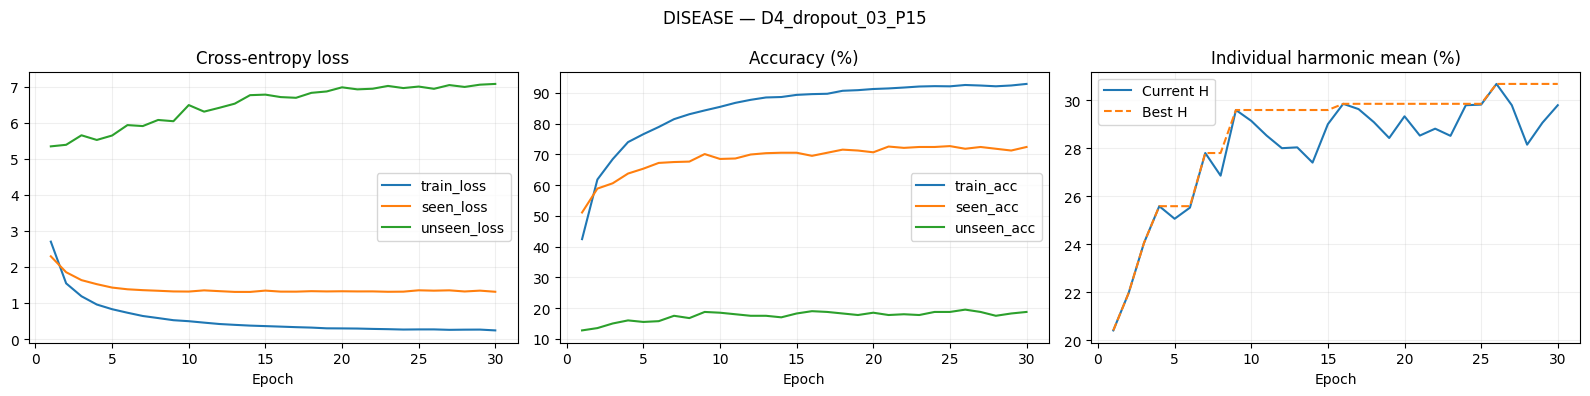


=== DISEASE: D5_dropout_04_P15 ===


DISEASE D5_dropout_04_P15 1/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D5_dropout_04_P15 | Epoch 01/30 | Train Loss 2.7603 | Train Acc 41.39% | Seen Val 50.65% | Unseen Val 13.00% | H 20.69% | Best H 20.69% | Patience 0/15


DISEASE D5_dropout_04_P15 2/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D5_dropout_04_P15 | Epoch 02/30 | Train Loss 1.6134 | Train Acc 59.96% | Seen Val 58.13% | Unseen Val 13.75% | H 22.24% | Best H 22.24% | Patience 0/15


DISEASE D5_dropout_04_P15 3/30:   0%|          | 0/216 [00:00<?, ?it/s]

... (51 outputs left out)

DISEASE D5_dropout_04_P15 29/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D5_dropout_04_P15 | Epoch 29/30 | Train Loss 0.3075 | Train Acc 90.54% | Seen Val 72.09% | Unseen Val 18.25% | H 29.13% | Best H 30.31% | Patience 3/15


DISEASE D5_dropout_04_P15 30/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D5_dropout_04_P15 | Epoch 30/30 | Train Loss 0.2859 | Train Acc 91.34% | Seen Val 72.37% | Unseen Val 18.75% | H 29.78% | Best H 30.31% | Patience 4/15
FINISHED disease/D5_dropout_04_P15: best epoch=26 | H=30.31%
COMPLETE disease/D5_dropout_04_P15 — Development validation only.


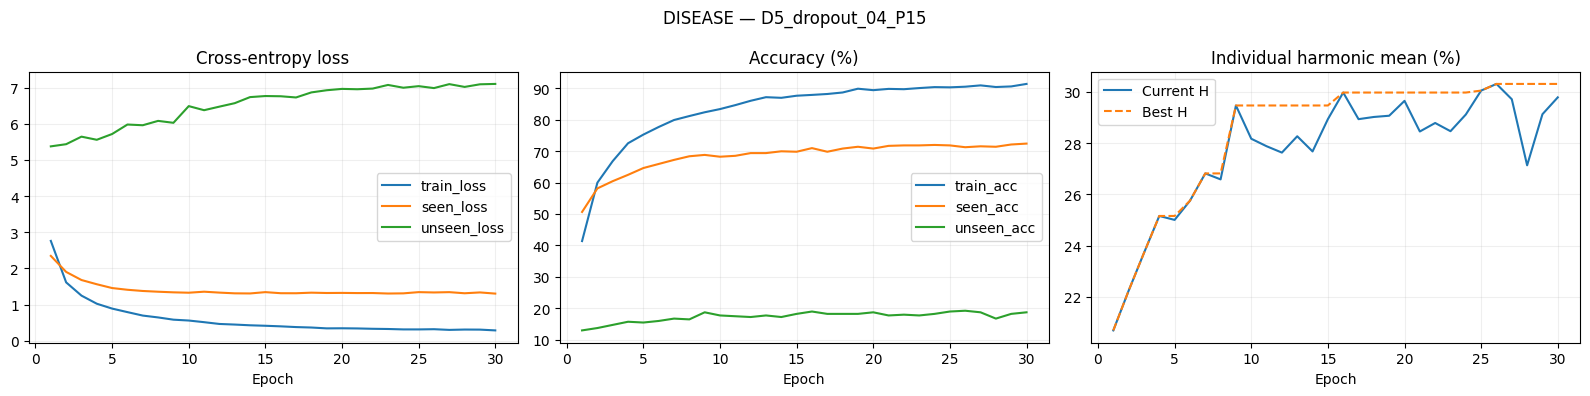

Disease dropout study training cell finished — NO OFFICIAL TEST.


In [ ]:
# STAGE 1 DEVELOPMENT VALIDATION ONLY — Disease dropout 0.3 / 0.4.
for name in RUN_DISEASE:
    print(f'\n=== DISEASE: {name} ===', flush=True)
    run_dropout_experiment('disease',name,DISEASE_EXPERIMENTS[name])
    if (experiment_path('disease',name)/'history.csv').exists():
        plot_experiment('disease',name)
print('Disease dropout study training cell finished — NO OFFICIAL TEST.')

## Cell 15 — DISEASE CNN: development validation experiment summary

Same table and fields as Crop Cell 12. Select disease configurations on development validation only; it is fine for Crop and Disease to have different optimal dropout.

In [ ]:
DISEASE_DROPOUT_RUNS=[REFERENCE_DISEASE_RUN,*DISEASE_EXPERIMENTS.keys()]
disease_summary=dropout_experiment_summary('disease',DISEASE_DROPOUT_RUNS)
disease_summary.to_csv(DROPOUT_DIR/'disease_individual_validation.csv',index=False)
print('Saved:',DROPOUT_DIR/'disease_individual_validation.csv')


STAGE 1 — DISEASE CNN DROPOUT DEVELOPMENT VALIDATION (NOT OFFICIAL TEST)


,experiment,dropout,best_epoch,trained_epochs,seen_validation_top1,unseen_validation_top1,seen_validation_top5,unseen_validation_top5,best_individual_H,backbone_lr,head_lr,patience
0,D1_reference_P15,0.2,26,30,71.80%,19.50%,88.49%,32.75%,30.67%,1.0e-05,1.0e-03,15
1,D4_dropout_03_P15,0.3,26,30,71.80%,19.50%,88.20%,32.00%,30.67%,1.0e-05,1.0e-03,15
2,D5_dropout_04_P15,0.4,26,30,71.22%,19.25%,88.06%,32.00%,30.31%,1.0e-05,1.0e-03,15


Saved: /content/drive/MyDrive/AML_B1_Clean_Results/development/dropout_tuning/disease_individual_validation.csv


## Cell 16 — Combine Crop and Disease checkpoints: rank **all 9,625** compositions

The model composition rule is **identical to Experiment 1**: sum the Crop and Disease log-probabilities for **55 × 175 = 9,625** candidate labels and compute top-1/top-5 accuracy. This uses **only the 695 seen and 400 unseen validation images**, not official test images.

In [ ]:
CANDIDATE_PAIRS = [(c,d) for c in crop_ids for d in disease_ids]
assert len(CANDIDATE_PAIRS) == 55*175 == 9625
candidate_to_index={p:i for i,p in enumerate(CANDIDATE_PAIRS)}

def composition_metrics(crop_lp,disease_lp,df,save_predictions=False):
    assert crop_lp.shape==(len(df),55), crop_lp.shape
    assert disease_lp.shape==(len(df),175), disease_lp.shape
    ctrue=np.array([crop_to_idx[int(c)] for c in df.crop_id],dtype=np.int64)
    dtrue=np.array([disease_to_idx[int(d)] for d in df.disease_id],dtype=np.int64)
    cpred=np.argsort(-crop_lp,axis=1)[:,:5]
    dpred=np.argsort(-disease_lp,axis=1)[:,:5]
    # Full 55x175 joint ranks; flatten order matches CANDIDATE_PAIRS.
    joint=(crop_lp[:,:,None]+disease_lp[:,None,:]).reshape(-1,9625)
    # Top 5 from all 9,625 (argpartition plus exact sorting inside candidate top-5).
    ix=np.argpartition(-joint,kth=4,axis=1)[:,:5]
    top5=ix[np.arange(len(df))[:,None],np.argsort(-np.take_along_axis(joint,ix,axis=1),axis=1)]
    true_ix=ctrue*175+dtrue
    metrics={
        'crop_top1':float(np.mean(cpred[:,0]==ctrue)),
        'crop_top5':float(np.mean((cpred==ctrue[:,None]).any(axis=1))),
        'disease_top1':float(np.mean(dpred[:,0]==dtrue)),
        'disease_top5':float(np.mean((dpred==dtrue[:,None]).any(axis=1))),
        'composition_top1':float(np.mean(top5[:,0]==true_ix)),
        'composition_top5':float(np.mean((top5==true_ix[:,None]).any(axis=1))),
    }
    if not save_predictions:return metrics,None
    records=[]
    for i,rec in enumerate(df.itertuples(index=False)):
        ranked=[CANDIDATE_PAIRS[int(j)] for j in top5[i]]
        records.append({
            'filename':rec.filename,
            'true_crop_id':int(rec.crop_id),'true_disease_id':int(rec.disease_id),
            'true_composition_id':int(rec.composition_id),
            'pred_crop_id':crop_ids[int(cpred[i,0])],
            'pred_disease_id':disease_ids[int(dpred[i,0])],
            'pred_pair_crop_id':ranked[0][0],
            'pred_pair_disease_id':ranked[0][1],
            'top5_compositions':json.dumps(ranked)
        })
    return metrics,pd.DataFrame(records)

print('Candidate catalogue:',len(CANDIDATE_PAIRS),'pairs')

Candidate catalogue: 9625 pairs


## Cell 17 — Compare all nine Dropout model pairs on development validation

Compares **three Crop models × three Disease models = nine model pairs**, each using the same 9,625 candidate compositions. Saves E3-only tables and a proposed best pair by **composition development H**. Does **not** overwrite E1/E2 development CSVs or select a final fine-tuning checkpoint.

In [ ]:
# STAGE 1 — COMBINED DEVELOPMENT VALIDATION ONLY (NO OFFICIAL TEST).
def get_best_validation_lp(task,name):
    path=experiment_path(task,name)/'best_validation.npz'
    assert path.exists(),f'Missing validation predictions: {path}'
    with np.load(path) as z:
        return {'seen':z['seen'].copy(),'unseen':z['unseen'].copy()}

crop_cache={name:get_best_validation_lp('crop',name) for name in CROP_DROPOUT_RUNS}
disease_cache={name:get_best_validation_lp('disease',name) for name in DISEASE_DROPOUT_RUNS}
comparison=[]
for cname,clp in crop_cache.items():
    for dname,dlp in disease_cache.items():
        sm,_=composition_metrics(clp['seen'],dlp['seen'],val_seen_df)
        um,_=composition_metrics(clp['unseen'],dlp['unseen'],val_unseen_df)
        comparison.append({
            'crop_run':cname,'disease_run':dname,
            'crop_dropout':float(crop_summary.set_index('experiment').loc[cname,'dropout']),
            'disease_dropout':float(disease_summary.set_index('experiment').loc[dname,'dropout']),
            'seen_composition_top1':sm['composition_top1'],
            'unseen_composition_top1':um['composition_top1'],
            'seen_composition_top5':sm['composition_top5'],
            'unseen_composition_top5':um['composition_top5'],
            'composition_H':harmonic(sm['composition_top1'],um['composition_top1'])
        })
comparison_df=pd.DataFrame(comparison).sort_values('composition_H',ascending=False).reset_index(drop=True)
print('STAGE 1 — E3 DROPOUT COMPOSITION DEVELOPMENT VALIDATION (NOT OFFICIAL TEST)')
print('Seen validation = 695; unseen validation = 400; candidate classes = 9,625')
display(comparison_df.style.format({
    'crop_dropout':'{:.1f}','disease_dropout':'{:.1f}',
    'seen_composition_top1':'{:.2%}','unseen_composition_top1':'{:.2%}',
    'seen_composition_top5':'{:.2%}','unseen_composition_top5':'{:.2%}',
    'composition_H':'{:.2%}'
}))
comparison_df.to_csv(DROPOUT_DIR/'checkpoint_pair_comparison.csv',index=False)
best_pair=comparison_df.iloc[0]
report={
    'stage':'Stage 1 development validation only',
    'selection_metric':'Highest combined composition validation H among E3 dropout candidate checkpoints',
    'crop_run':str(best_pair['crop_run']), 'disease_run':str(best_pair['disease_run']),
    'candidate_classes':9625, 'seen_validation_images':len(val_seen_df),
    'unseen_validation_images':len(val_unseen_df),
    'seen_composition_top1':float(best_pair['seen_composition_top1']),
    'unseen_composition_top1':float(best_pair['unseen_composition_top1']),
    'composition_H':float(best_pair['composition_H'])
}
(DROPOUT_DIR/'best_dropout_pair_development.json').write_text(json.dumps(report,indent=2))
print(f"BEST E3 VALIDATION PAIR: {report['crop_run']} + {report['disease_run']} | H {report['composition_H']:.2%}")
print('Saved E3-only results to:',DROPOUT_DIR)
print('NO FINE-TUNING. NO OFFICIAL TEST DATA USED.')

STAGE 1 — E3 DROPOUT COMPOSITION DEVELOPMENT VALIDATION (NOT OFFICIAL TEST)
Seen validation = 695; unseen validation = 400; candidate classes = 9,625


,crop_run,disease_run,crop_dropout,disease_dropout,seen_composition_top1,unseen_composition_top1,seen_composition_top5,unseen_composition_top5,composition_H
0,C4_dropout_03_P15,D1_reference_P15,0.3,0.2,68.20%,5.75%,84.46%,12.25%,10.61%
1,C4_dropout_03_P15,D4_dropout_03_P15,0.3,0.3,68.20%,5.50%,84.17%,11.75%,10.18%
2,C4_dropout_03_P15,D5_dropout_04_P15,0.3,0.4,67.48%,5.00%,84.60%,12.00%,9.31%
3,C5_dropout_04_P15,D1_reference_P15,0.4,0.2,66.47%,5.00%,83.02%,11.25%,9.30%
4,C1_reference_P15,D1_reference_P15,0.2,0.2,67.91%,4.75%,84.46%,11.75%,8.88%
5,C5_dropout_04_P15,D4_dropout_03_P15,0.4,0.3,66.47%,4.75%,82.88%,10.75%,8.87%
6,C1_reference_P15,D4_dropout_03_P15,0.2,0.3,67.91%,4.50%,84.32%,11.25%,8.44%
7,C5_dropout_04_P15,D5_dropout_04_P15,0.4,0.4,65.90%,4.25%,82.88%,10.75%,7.99%
8,C1_reference_P15,D5_dropout_04_P15,0.2,0.4,67.19%,4.00%,84.32%,11.75%,7.55%


BEST E3 VALIDATION PAIR: C4_dropout_03_P15 + D1_reference_P15 | H 10.61%
Saved E3-only results to: /content/drive/MyDrive/AML_B1_Clean_Results/development/dropout_tuning
NO FINE-TUNING. NO OFFICIAL TEST DATA USED.


## Run checklist / where to edit

1. Enable a Colab GPU, then run Cells **1–10** sequentially. Cell 7 reproduces Experiment 1's visual augmentation check; it does **not** train anything.
2. Run **Cell 11** to train the Crop dropout experiments. To run only one, edit `RUN_CROP` in Cell 10.
3. Run **Cell 12** to read Crop results. It requires both C4 and C5 to be completed.
4. Run **Cells 13–14** to configure and train Disease dropout experiments. Edit `RUN_DISEASE` to run only one.
5. Run **Cells 15–17** to produce individual and combined **development validation** comparisons.

**Saved checkpoints:** `MyDrive/AML_B1_Clean_Results/experiments/crop|disease/<run_name>/`.

**Saved E3 comparisons only:** `MyDrive/AML_B1_Clean_Results/development/dropout_tuning/`.

**Existing experiments are preserved.** If a new run has a `best.pt` but no `STAGE1_COMPLETE.json`, the notebook stops for inspection rather than overwriting it. The base E1/E2 training function does not support resuming partial runs.

**E3 does not fine-tune or test on the official 2,000/1,448-image sets.**